# 5 Brownian dynamics

## Random walks and discrete white noise

<div style="background-color:#f0f8ff; border:2px solid #4682b4; padding:12px; border-radius:4px;">
<strong>Note:</strong> This notebook contains the code for sections 5.1-5.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

To study Brownian motion (erratic motion of a microscopic particle due to the collisions with the molecules of the surrounding fluid)  we start from the concept of random walk.

**Historical reference:** Einstein (1905), *On the motion of small particles suspended in liquids at rest*, Annalen der Physik **17**, 208 (textbook reference [2]).

<a id="random-walk"></a>
## 5.1 Random walks and universality

For symmetric independent steps: $w_i\in\{-1,+1\}$, starting from $x_0 = 0$

$x_{i+1}=x_i+w_i \qquad$ Eq. (5.1)

Since $\langle w_i\rangle=0$ and $\langle w_i^2\rangle=1$ :

Ensemble mean: $\langle x_n\rangle=0$

MSD: $\langle x_n^2\rangle=n$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()  

Let's generate a random walk with symmetric independent steps:

In [2]:
n_steps = 1000
steps = rng.choice([-1, 1], size=n_steps)
positions = np.zeros(n_steps + 1)
for i in range(n_steps):
    positions[i + 1] = positions[i] + steps[i]

Let's plot it:

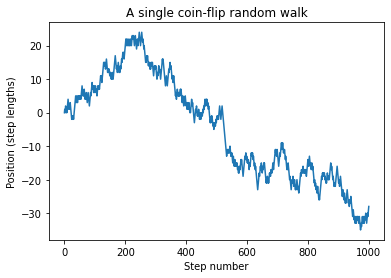

In [3]:
plt.plot(np.arange(n_steps + 1), positions)
plt.xlabel("Step number")
plt.ylabel("Position (step lengths)")
plt.title("A single coin-flip random walk");

To measure an ensemble property, we need to generate a sufficiently large number of independent random walks.

In [4]:
n_walkers = 800  # number of independent random walkers
n_steps = 1000  # number of steps 

all_steps = rng.choice([-1, 1], size=(n_steps, n_walkers))
walks = np.zeros((n_steps + 1, n_walkers))

for i in range(n_steps):
    walks[i + 1] = walks[i] + all_steps[i]

Let's plot the independent random walks:

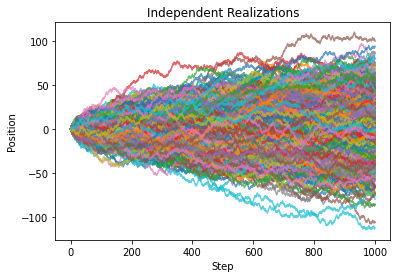

In [5]:
# plot the independent realizations

plt.figure(figsize=(6, 4))
plt.plot(walks, alpha=0.7)
plt.xlabel("Step")
plt.ylabel("Position")
plt.title("Independent Realizations")
plt.show()

Let's plot the ensemble properties (mean, MSD):

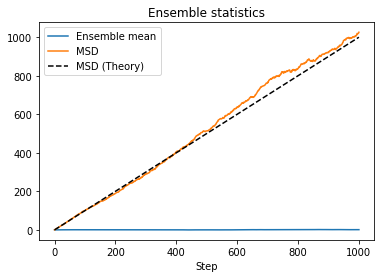

In [6]:
# plot ensemble properties

plt.figure(figsize=(6, 4))
plt.plot(walks.mean(axis=1), label="Ensemble mean")
plt.plot(np.mean(walks**2, axis=1), label="MSD")
plt.plot(np.arange(n_steps + 1), "k--", label="MSD (Theory)")
plt.legend()
plt.xlabel("Step") 
plt.title("Ensemble statistics")
plt.show();

<a id="universality"></a>
### Exercise 5.1 — Universality

Let's compares random walks originated via three **different** step distributions with the **same mean and variance**:

1. **flip-coin** (symmetric independent steps): $w_i\in\{-1,+1\}$
2. **Gaussian steps** $w_i\in\, \mathcal N(0,1) \qquad$ 
3. **three-values** (asymmetric independent steps): $w_i\in\left\{-1,\, (1 - \sqrt{3})\, / 2,\, (1 + \sqrt{3})\, / 2 \right\}$

First, let's check that the **three-values** step distribution has $\langle w_i\rangle=0$ and $\langle w_i^2\rangle=1$.

In [7]:
three_values = np.array([-1, (1 - np.sqrt(3)) / 2,
                         (1 + np.sqrt(3)) / 2])
print("Mean:", three_values.mean())
print(
    "Variance:", 
    ((three_values - three_values.mean())**2).mean()
)

Mean: 0.0
Variance: 1.0


We generate the steps:

In [8]:
n_walkers = 1000  # number of independent random walkers
n_steps = 1000  # number of steps 

flip_steps = rng.choice([-1., 1.], size=(n_steps, n_walkers))
normal_steps = rng.standard_normal((n_steps, n_walkers))
three_steps = rng.choice(three_values, size=(n_steps, n_walkers))

We generate the corresponding random walks:

In [9]:
flip_walks = np.vstack(
    (np.zeros(n_walkers), 
     np.cumsum(flip_steps, axis=0))
)

normal_walks = np.vstack(
    (np.zeros(n_walkers), 
     np.cumsum(normal_steps, axis=0))
)

three_walks = np.vstack(
    (np.zeros(n_walkers), 
     np.cumsum(three_steps, axis=0))
)

We plot the generated independent random walks:

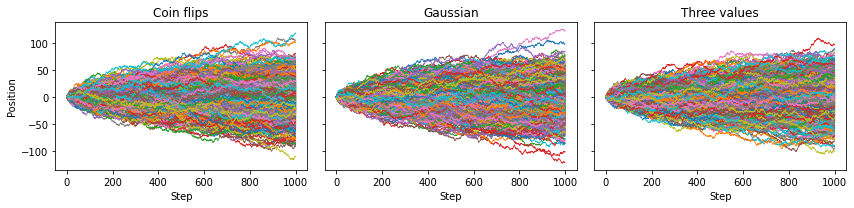

In [10]:
fig, axes = plt.subplots(
    1, 3, 
    figsize=(12, 3), 
    sharex=True, 
    sharey=True
)

for ax, trajectory, name in zip(
    axes, 
    [flip_walks, normal_walks, three_walks],
    ["Coin flips", "Gaussian", "Three values"]
):
    ax.plot(trajectory[:, :], lw=0.8)
    ax.set(
        title=name, 
        xlabel="Step"
    )
axes[0].set_ylabel("Position")
plt.tight_layout();

Let's check the final position distribution for each of the different steps distributions:

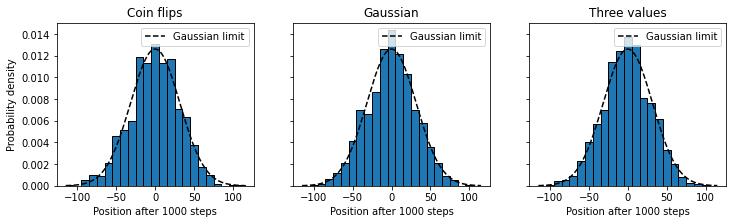

In [11]:
final_positions = [
    flip_walks[-1], 
    normal_walks[-1], 
    three_walks[-1]
]

xx = np.linspace(-115, 115, 300)

fig, axes = plt.subplots(
    1, 3, 
    figsize=(12, 3), 
    sharex=True, 
    sharey=True
)

for ax, values, name in zip(
    axes,
    final_positions, 
    ["Coin flips", "Gaussian", "Three values"]
):
    ax.hist(
        values, 
        bins=np.arange(-115, 121, 10), 
        density=True,
        histtype="bar", 
        edgecolor="black",
        lw=1.0, 
    )
    ax.plot(
        xx, 
        np.exp(-xx ** 2 / (2 * n_steps)) 
        / np.sqrt(2 * np.pi * n_steps),
        "k--", 
        label="Gaussian limit"
    )
    ax.set(
        xlabel="Position after 1000 steps", 
        title=name, 
    )
    ax.legend();
axes[0].set_ylabel("Probability density");


<a id="white-noise"></a>
## 5.2 Discrete white noise

We consider the problem of observing a random walker moving with random Gaussian-distributed steps at different frame rates (observation times are spaced by an amount $\Delta t$).

Brownian motion / Wiener process / diffusion process: solution of $\dot{x}=W(t)$ (Eq. 5.2), where $W(t)$ is white noise.

Discretized as: $x(t+\Delta t)=x(t)+\sqrt{\Delta t}\,w_i$ (Eq. 5.3), with $w_i\sim\mathcal{N}(0,1)$.

If the diffusion coefficient is $D$:

$$
x(t+\Delta t)=x(t)+\sqrt{2D\Delta t}\,w_i
$$

Units of $D$: $\mathrm{m^2/s}$.

Mean square displacement of the process: $\mathrm{MSD}(t)=2Dt$ in one dimension.

Let's generate the physical trajectories for same physical diffusion process (diffusion coefficient $D$) with different choices of the time step:

In [12]:
n_traj = 1000
step_sizes = [0.01, 0.05, 0.1]
duration = 5.0
D = 2.0

increments_list = []
tracks_list = []

for dt in step_sizes:
    n = round(duration / dt)
    increments = (
        np.sqrt(2 * D * dt) 
        * rng.standard_normal((n, n_traj))
    )
    tracks = (
        np.vstack(
            (np.zeros(n_traj), 
             np.cumsum(increments, axis=0))
        )
    )
    increments_list.append(increments)
    tracks_list.append(tracks)
    

Let's plot:

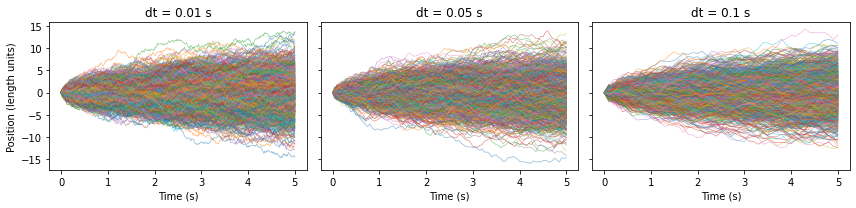

In [13]:
fig, axes = plt.subplots(
    1, 3, 
    figsize=(12, 3), 
    sharex=True, 
    sharey=True
)
for ax, dt, tracks in zip(axes, step_sizes, tracks_list):
    n = tracks.shape[0]
    ax.plot(
        np.arange(n) * dt, 
        tracks, 
        lw=0.65, 
        alpha=0.55
    )
    ax.set(
        title=f"dt = {dt} s", 
        xlabel="Time (s)"
    )
axes[0].set_ylabel("Position (length units)")
plt.tight_layout();

If you want to plot only few single trajectories: plot  `tracks[:,:k]` (with `k` set to the number of independent walks to the plotted) instead of `track` 

Let's plot the MSD

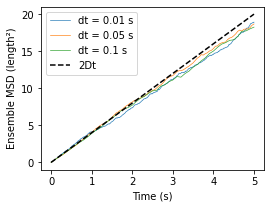

In [14]:
plt.figure(figsize=(4, 3))
for dt, tracks in zip(step_sizes, tracks_list):
    n = tracks.shape[0]
    plt.plot(
        np.arange(n) * dt, 
        np.mean(tracks ** 2, axis=1), 
        lw=0.65, 
        label=f"dt = {dt} s"
    )
t = np.linspace(0, duration)
plt.plot(t, 2 * D * t, "k--", label="2Dt")
plt.xlabel("Time (s)")
plt.ylabel("Ensemble MSD (length²)")
plt.legend();

<a id="module"></a>
Let's use the module `brownian_dynamics.py` :

In [15]:
# The same calculations, now available as a reusable module.
from pathlib import Path
import sys
sys.path.insert(0, "../05_modules")
import brownian_dynamics as bd

Let's see how to use it for generating a set of random walks:

In [16]:
walks = bd.random_walks(
    n_walkers=10000, 
    n_steps=50, 
    kind="three"
)

print("Final-position variance (walk):", np.var(walks[-1]))

Final-position variance (walk): 50.315082035479506


Let's see how to use it for generating a free-diffusion process with diffusion $D$, observed at intervals of $\Delta t$

In [17]:
n_walkers = 10000
dt = 0.01
duration = 5.0
D = 2.0

free_diff = bd.free_diffusion(
    n_walkers=n_walkers, 
    duration=duration,
    dt=dt, 
    diffusion=D
)

Let's estimate the diffusion coefficient:

In [18]:
final_pos_variance = np.var(free_diff[-1])

D_empirical = final_pos_variance / (2 * duration)
print(f'D_empirical = {D_empirical:.5f}')
print(f'D = {D:.5f}')

delta_D = abs(D_empirical - D)

print(f'Absolute error: {delta_D:.6f}')
print(f'Relative error: {delta_D / D:.6f}')

D_empirical = 2.00454
D = 2.00000
Absolute error: 0.004539
Relative error: 0.002269


<a id="questions"></a>

## Questions

Here you find the questions:

- [Q1: Random walk](#q1)
- [Q2: Universality](#q2)
- [Q3: White noise](#q3)
- [Q4: Module](#q4)

<a id="q1"></a>
**Question 1: Random walk.**  

Refer to [Random walk](#random-walk).  

[Go back to questions](#questions)

a. Suppose we modify the random walk by introducing a probability `q` of stepping to the right:
```python
    n_walkers = 800
    n_steps = 1000
    q = 0.5

    all_steps = rng.choice(
        [-1, 1],
        size=(n_steps, n_walkers),
        p=[1-q, q]
    )

    walks = np.zeros((n_steps + 1, n_walkers))

    for i in range(n_steps):
        walks[i + 1] = walks[i] + all_steps[i]
```
Would we recover the original results for `q = 0.5`? Why?

b. How do the trajectories and ensemble mean change for `q = 0.55`,  `q = 0.6`, and `q = 0.8` ?

c. How does the MSD change for `q = 0.55`,  `q = 0.6`, and `q = 0.8` ? Does it still grow linearly with the number of steps?  Explain why or why not.

<a id="q2"></a>
**Question 2: Universality.** 

Refer to [Universality](#universality).  

[Go back to questions](#questions)

a. Suppose we modify the three-value random walk by introducing a probability parameter `p`:
```python
    p = 1/3

    three_values = [-1 / np.sqrt(2 * p), 0., 1 / np.sqrt(2 * p)]
    three_probs = [p, 1 - 2 * p, p]

    three_steps = rng.choice(
        three_values,
        size=(n_steps, n_walkers),
        p=three_probs
    )

    three_walks = np.vstack(
        (np.zeros(n_walkers),
         np.cumsum(three_steps, axis=0))
    )
```
Would the distribution of final positions still approach the same Gaussian distribution after sufficiently many steps? Explain why or why not.

b. Suppose we gradually decrease `p` from 1/3 to 0.1, 0.01, and 0.001, but keep `n_steps` fixed. How would the individual trajectories and final-position distributions change?

c. For `p = 0.001`, suppose we increase the number of steps `n_steps`. What do you expect to observe?

<a id="q3"></a>
**Question 3: White noise.**  

Refer to [White noise](#white-noise).  

[Go back to questions](#questions)

a. In the notebook, Brownian motion is simulated using different time steps, `step_sizes = [0.01, 0.05, 0.1]`. Why do the trajectories show similar behavior despite the different time resolutions?

b. Suppose we replace $\sqrt{\Delta t}$ with $\Delta t$ in the random displacements. How would the trajectories change? Would the results still be independent of the time step? Explain why or why not.

c. Consider the following code:
```python
    ax.plot(
        np.arange(n) * dt, 
        tracks, 
        lw=0.65, 
        alpha=0.55
    )
```
Suppose you want to plot only every tenth trajectory instead of all trajectories. How would you modify the code? Explain your reasoning.

<a id="q4"></a>

**Question 4: Module.**  

Refer to [the section using the module](#module) and  [brownian_dynamics.py](../05_modules/brownian_dynamics.py).  

[Go back to questions](#questions)

a. Compare `random_walks()` and `free_diffusion()` in the module. Could you reproduce the behavior of `free_diffusion()` using `random_walks()`? What would you need to change?

b. Suppose you use `random_walks()` with `kind="flip"` instead of `kind="normal"`, applying the same scaling. Would you expect the resulting motion to have the same statistical properties as `free_diffusion()`? Explain why or why not.